# Notebook 05 — Final Evaluation and Error Analysis

This notebook loads the model, hyperparameters and threshold fixed in Notebook 04, predicts the 9,043 untouched test clients **once**, and analyses the results and errors. Nothing is re-tuned after looking at the test results. Run the notebooks in the order 01 → 05 and execute all cells from the top (*Restart* → *Run All*).

## 1. Setup and Loading the Saved Model

This section imports the libraries, recreates the identical split and loads the saved pipeline and its metadata.

In [1]:
# Make the project's src/ package importable (notebooks live in notebooks/)
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

# Hide FutureWarnings from libraries so that the outputs stay readable
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report

# Project modules: figure style, paths, evaluation plots and the prediction helper used by the app
from src.plot_style import apply_style, BLUE, ORANGE
from src.config import FIGURES_DIR, RESULTS_DIR
from src.data_loader import load_raw_data
from src.preprocessing import split_data, build_model_pipeline
from src.evaluate import (get_scores, classification_metrics, plot_confusion_matrix,
                          plot_roc_curve, plot_precision_recall_curve)
from src.predict import load_model, predict_customer

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Identical split (random_state=42)
df = load_raw_data()
X_train, X_test, y_train, y_test = split_data(df)

# Saved pipeline (preprocessing + model) and the threshold chosen on training data
model, meta = load_model()
THRESHOLD = meta["decision_threshold"]
print("Final model    :", meta["model_name"])
print("Hyperparameters:", meta["best_params"])
print(f"Threshold      : {THRESHOLD:.4f} (chosen on out-of-fold training predictions)")
print("Test set       :", X_test.shape, f"| share of yes = {y_test.mean():.4f}")

Final model    : Gradient Boosting
Hyperparameters: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}
Threshold      : 0.1828 (chosen on out-of-fold training predictions)
Test set       : (9043, 15) | share of yes = 0.1170


## 2. Final Evaluation on the Test Set

This section scores the test set once and compares the final model at the pre-chosen threshold with the 0.5 threshold (reference only) and the majority-class baseline.

In [2]:
# The only time the model sees the test set
test_scores = get_scores(model, X_test)
y_pred = (test_scores >= THRESHOLD).astype(int)

# Majority-class baseline fitted on the training set
dummy = build_model_pipeline(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
dummy_scores = get_scores(dummy, X_test)

final_results = pd.DataFrame({
    f"Final model (threshold {THRESHOLD:.3f})": classification_metrics(y_test, y_pred, test_scores),
    "Final model (threshold 0.5, reference)": classification_metrics(y_test, (test_scores >= 0.5).astype(int), test_scores),
    "Baseline: majority class": classification_metrics(y_test, dummy.predict(X_test), dummy_scores),
}).round(4)
final_results

,Final model (threshold 0.183),"Final model (threshold 0.5, reference)",Baseline: majority class
accuracy,0.8739,0.8977,0.883
precision,0.4665,0.6475,0.000
recall,0.5397,0.2760,0.000
f1,0.5004,0.3870,0.000
roc_auc,0.8056,0.8056,0.500
average_precision,0.4692,0.4692,0.117


In [3]:
# Per-class precision, recall and F1 at the chosen threshold
print(classification_report(y_test, y_pred, target_names=["no", "yes"], digits=3))

              precision    recall  f1-score   support

          no      0.938     0.918     0.928      7985
         yes      0.467     0.540     0.500      1058

    accuracy                          0.874      9043
   macro avg      0.702     0.729     0.714      9043
weighted avg      0.883     0.874     0.878      9043



**Interpretation.** On 9,043 unseen clients the model reaches **ROC-AUC 0.806** and average precision 0.469 (4× the random level of 0.117). At threshold 0.183 it finds **54.0 %** of subscribers with a precision of **46.7 %** (F1 = 0.500 vs 0 for the baseline). The baseline (88.3 %) and the 0.5 threshold (89.8 %) are *more accurate* than our choice (87.4 %) but find far fewer subscribers, which confirms that accuracy is not the right metric.

## 3. Confusion Matrix

This section shows the four types of correct and incorrect predictions at the chosen threshold.

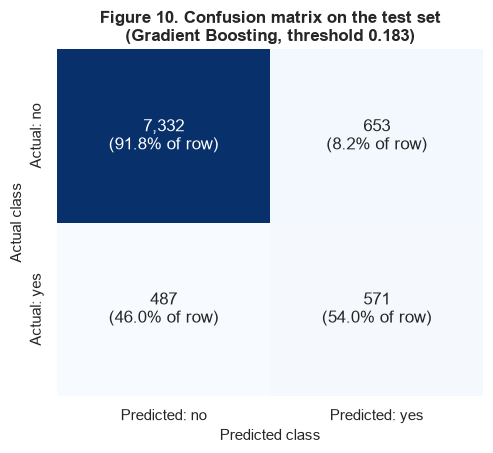

TN=7,332  FP=653  FN=487  TP=571


In [4]:
# Figure 10: confusion matrix on the test set
fig = plot_confusion_matrix(y_test, y_pred,
                            f"Figure 10. Confusion matrix on the test set\n({meta['model_name']}, threshold {THRESHOLD:.3f})",
                            filename="fig10_confusion_matrix.png")
plt.show()
tn, fp, fn, tp = pd.crosstab(y_test, y_pred).values.ravel()
print(f"TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")

**Interpretation (Figure 10).** Of 1,058 subscribers, **571 are found** and **487 are missed**; of 7,985 non-subscribers, 653 would be called in vain. About 4.7 of every 10 recommended calls lead to a subscription, compared with about 1.2 when calling at random.

## 4. ROC and Precision-Recall Curves

This section shows the ranking quality over all possible thresholds.

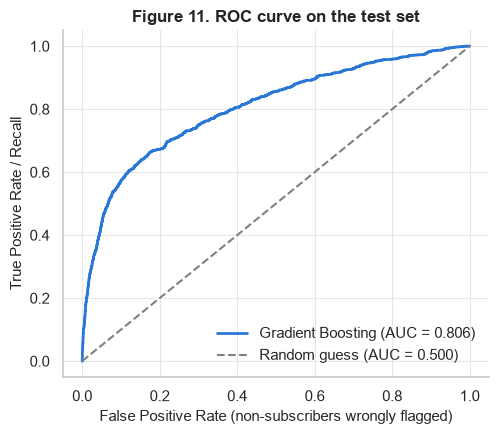

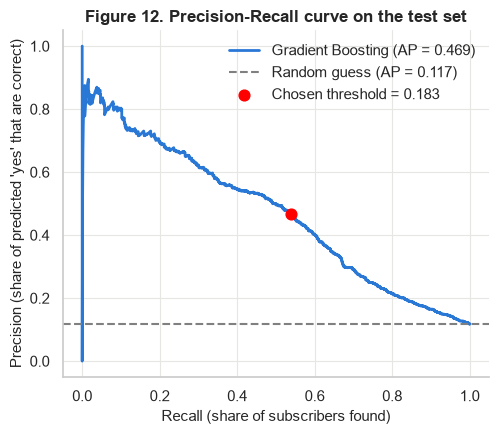

In [5]:
# Figure 11: ROC curve; Figure 12: precision-recall curve with the chosen operating point
fig = plot_roc_curve(y_test, test_scores, meta["model_name"],
                     "Figure 11. ROC curve on the test set", filename="fig11_roc_curve.png")
plt.show()
fig = plot_precision_recall_curve(y_test, test_scores, meta["model_name"],
                                  "Figure 12. Precision-Recall curve on the test set",
                                  threshold=THRESHOLD, filename="fig12_precision_recall_curve.png")
plt.show()

**Interpretation (Figures 11–12).** The ROC curve lies well above the diagonal (AUC 0.806). Precision is about 0.8 for the top-ranked clients and falls as more subscribers are sought; the red point marks the operating point chosen on training data (recall 0.54, precision 0.47).

## 5. Cumulative Gains

This section measures how many subscribers the bank reaches by calling the top-ranked clients first.

In [6]:
# Cumulative share of subscribers reached when clients are called from highest to lowest score
order = np.argsort(-test_scores)
gains = np.cumsum(y_test.values[order]) / y_test.sum()

# Summary at 10 %, 20 %, 30 % and 50 % of clients called, with the lift over random calling
gain_rows = []
for pct in [10, 20, 30, 50]:
    g = gains[int(len(order) * pct / 100) - 1] * 100
    gain_rows.append({"top % of clients called": pct, "% of subscribers reached": round(g, 1),
                      "lift vs random": round(g / pct, 2)})
gains_table = pd.DataFrame(gain_rows)
gains_table

,top % of clients called,% of subscribers reached,lift vs random
0,10,45.4,4.54
1,20,62.7,3.13
2,30,71.0,2.37
3,50,83.6,1.67


**Interpretation.** Calling the **top 10 %** of clients ranked by the model reaches **45.4 %** of all subscribers (lift 4.5×), and the **top 20 %** reaches **62.7 %** (lift 3.1×). This ranking is the most useful output for the bank: it can choose how many calls it can afford and call clients in score order.

## 6. Over-fitting and Bias–Variance: Train vs CV vs Test

This section compares the final model's scores on the training set, in cross-validation and on the test set.

In [7]:
# Same metrics on the training set (re-substitution), in 5-fold CV (Notebook 04) and on the test set
train_scores = get_scores(model, X_train)
fit_table = pd.DataFrame({
    "Training set (re-substitution)": classification_metrics(y_train, (train_scores >= THRESHOLD).astype(int), train_scores),
    "5-fold CV (Notebook 04)": {m: meta["cv_summary"].get(m, np.nan) for m in
                                ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]},
    "Test set": classification_metrics(y_test, y_pred, test_scores),
}).round(4)
fit_table

,Training set (re-substitution),5-fold CV (Notebook 04),Test set
accuracy,0.8882,0.8938,0.8739
precision,0.5190,0.6099,0.4665
recall,0.6027,0.2553,0.5397
f1,0.5577,0.3597,0.5004
roc_auc,0.8523,0.7995,0.8056
average_precision,0.6233,0.4485,0.4692


**Interpretation.**
* ROC-AUC is 0.852 on training data, 0.800 in CV and **0.806** on the test set: a train–test gap of ≈0.05 indicates **mild over-fitting**, far smaller than for the unlimited Decision Tree (1.000 vs 0.605) or the default Random Forest (1.000 vs 0.778).
* The test score agrees with the CV estimate, so model selection did not over-fit the validation folds, and the test F1 (0.500) is close to the out-of-fold F1 at the same threshold (0.490). (The CV column uses threshold 0.5 for F1/precision/recall, because GridSearchCV scores with `predict`.)
* **Bias–variance:** Logistic Regression had high bias, single trees and KNN high variance; tuned boosting sits between them, and the learning-curve table in Notebook 04 shows that the remaining error is mostly bias / missing information.

## 7. Permutation Importance

This section shuffles one original column at a time on the test set and measures the drop in ROC-AUC (interpretation only, not model selection); the full result is saved and the 8 most important features are shown.

In [8]:
# Mean and std of the ROC-AUC drop over 5 random shuffles per feature
perm = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=5,
                              random_state=42, n_jobs=-1)
imp = pd.DataFrame({"feature": X_test.columns, "mean_drop_auc": perm.importances_mean,
                    "std": perm.importances_std}).sort_values("mean_drop_auc")
imp.to_csv(RESULTS_DIR / "permutation_importance_test.csv", index=False)

# Short table: the 8 most important features (largest ROC-AUC drop first)
imp.sort_values("mean_drop_auc", ascending=False).head(8).round(4).reset_index(drop=True)

,feature,mean_drop_auc,std
0,month,0.0954,0.0047
1,contact,0.0678,0.0014
2,day,0.0354,0.0029
3,poutcome,0.0237,0.0021
4,pdays,0.0103,0.0012
5,age,0.0102,0.0016
6,balance,0.0078,0.0017
7,campaign,0.0076,0.0014


**Interpretation.** The model relies most on **month** (AUC drop 0.095), **contact** (0.068), **day** (0.035) and **poutcome** (0.024). Because month and day describe *when* a client was called and the data are ordered in time (May 2008 – Nov 2010), part of this importance may reflect the campaign period rather than the client.

## 8. Error Analysis

### 8.1 Performance by Customer Group

This section computes, for each group, the number of test clients, the actual subscription rate, recall, precision and the number of errors.

In [9]:
# Test predictions with the age group and the error type of every client
res = X_test.copy()
res["actual"] = y_test.values
res["pred"] = y_pred
res["score"] = test_scores
res["age_group"] = pd.cut(res["age"], [17, 25, 30, 40, 50, 60, 100],
                          labels=["18-25", "26-30", "31-40", "41-50", "51-60", "61+"])
res["error_type"] = np.select([(res.actual == 1) & (res.pred == 0), (res.actual == 0) & (res.pred == 1)],
                              ["false negative", "false positive"], "correct")


def group_report(col):
    """Size, actual yes-rate, recall, precision and error counts per value of `col`."""
    g = res.groupby(col, observed=True)
    out = pd.DataFrame({
        "n": g.size(),
        "actual_yes_rate": g["actual"].mean(),
        "recall": g.apply(lambda t: t.loc[t.actual == 1, "pred"].mean() if t.actual.sum() else np.nan),
        "precision": g.apply(lambda t: t.loc[t.pred == 1, "actual"].mean() if t.pred.sum() else np.nan),
        "false_neg": g.apply(lambda t: ((t.actual == 1) & (t.pred == 0)).sum()),
        "false_pos": g.apply(lambda t: ((t.actual == 0) & (t.pred == 1)).sum()),
    })
    return out.round(3)


# Group reports for five features (all saved; four displayed)
segments = {c: group_report(c) for c in ["poutcome", "contact", "age_group", "month", "housing"]}
pd.concat(segments, names=["feature", "group"]).to_csv(RESULTS_DIR / "error_analysis_by_group.csv")
for c in ["poutcome", "contact", "age_group", "housing"]:
    print(f"\n=== {c} ===")
    display(segments[c])


=== poutcome ===


,n,actual_yes_rate,recall,precision,false_neg,false_pos
poutcome,,,,,,
failure,1012,0.138,0.571,0.367,60,138
other,355,0.175,0.613,0.418,24,53
success,306,0.650,1.000,0.652,0,106
unknown,7370,0.089,0.387,0.416,403,356



=== contact ===


,n,actual_yes_rate,recall,precision,false_neg,false_pos
contact,,,,,,
cellular,5820,0.153,0.577,0.479,376,557
telephone,589,0.114,0.716,0.378,19,79
unknown,2634,0.039,0.107,0.393,92,17



=== age_group ===


,n,actual_yes_rate,recall,precision,false_neg,false_pos
age_group,,,,,,
18-25,257,0.222,0.772,0.436,13,57
26-30,1070,0.144,0.545,0.438,70,108
31-40,3552,0.104,0.480,0.466,193,204
41-50,2256,0.088,0.437,0.460,112,102
51-60,1689,0.108,0.492,0.539,93,77
61+,219,0.429,0.936,0.456,6,105



=== housing ===


,n,actual_yes_rate,recall,precision,false_neg,false_pos
housing,,,,,,
no,4095,0.166,0.676,0.483,220,492
yes,4948,0.077,0.296,0.410,267,161


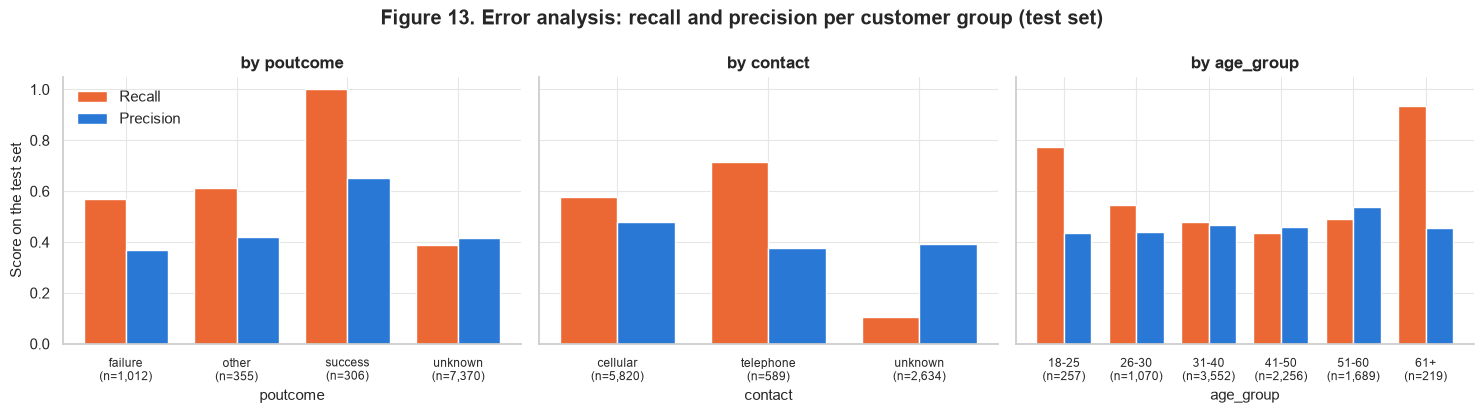

In [10]:
# Figure 13: recall and precision per group for three features
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, col in zip(axes, ["poutcome", "contact", "age_group"]):
    s = segments[col]
    x = np.arange(len(s))
    w = 0.38
    ax.bar(x - w / 2, s["recall"], w, color=ORANGE, label="Recall")
    ax.bar(x + w / 2, s["precision"], w, color=BLUE, label="Precision")
    ax.set_xticks(x, [f"{i}\n(n={n:,})" for i, n in zip(s.index.astype(str), s["n"])], fontsize=8.5)
    ax.set_title(f"by {col}")
    ax.set_xlabel(col)
axes[0].set_ylabel("Score on the test set")
axes[0].legend(loc="upper left")
fig.suptitle("Figure 13. Error analysis: recall and precision per customer group (test set)", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig13_error_analysis_groups.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation (Figure 13 and tables).**
* **Previous outcome:** recall is 1.00 for `success`, but only **0.39** for `unknown` (no previous campaign, 81.5 % of test clients), which contains **403 of the 487 false negatives (83 %)**.
* **Contact = unknown:** recall only **0.11**. These clients were almost all called in May–June of the early campaigns, when the contact type was not recorded and success rates were low (4.8 % in the first half of the time-ordered file vs 18.6 % in the second).
* **Age:** recall is high for 18–25 (0.77) and 61+ (0.94) and lower for 31–50 (≈0.44–0.48), where subscribers resemble the majority of non-subscribers.
* **Housing loan:** recall 0.68 without vs 0.30 with a housing loan.

### 8.2 Typical False Negatives and False Positives

This section lists the most confident errors and compares the average profile of each outcome group.

In [11]:
# Most confident errors: subscribers with the lowest scores and non-subscribers with the highest scores
show = ["age", "job", "balance", "housing", "loan", "contact", "month", "campaign", "poutcome", "score"]
print("Most confident FALSE NEGATIVES (subscribed, but the model gave a low score):")
display(res[res.error_type == "false negative"].nsmallest(5, "score")[show].round(3))
print("Most confident FALSE POSITIVES (did not subscribe, but the model gave a high score):")
display(res[res.error_type == "false positive"].nlargest(5, "score")[show].round(3))

Most confident FALSE NEGATIVES (subscribed, but the model gave a low score):


,age,job,balance,housing,loan,contact,month,campaign,poutcome,score
6854,57,retired,0,yes,yes,unknown,may,1,unknown,0.021
3378,41,admin.,-306,yes,no,unknown,may,1,unknown,0.022
6005,59,services,-22,yes,no,unknown,may,3,unknown,0.024
891,53,services,-291,yes,yes,unknown,may,1,unknown,0.025
7281,56,technician,589,yes,no,unknown,may,2,unknown,0.025


Most confident FALSE POSITIVES (did not subscribe, but the model gave a high score):


,age,job,balance,housing,loan,contact,month,campaign,poutcome,score
45110,50,management,8205,yes,no,telephone,oct,3,other,0.965
44678,60,admin.,12980,no,no,cellular,sep,2,success,0.908
43135,25,student,469,no,no,cellular,feb,1,success,0.888
45098,44,technician,11115,no,no,cellular,oct,1,success,0.882
42717,61,management,13546,no,no,cellular,jan,2,success,0.873


In [12]:
# Average profile of true/false positives and negatives
outcome = np.select([(res.actual == 1) & (res.pred == 1), res.error_type == "false negative",
                     res.error_type == "false positive"],
                    ["true positive", "false negative", "false positive"], "true negative")
profile = res.groupby(outcome)
pd.DataFrame({
    "n": profile.size(),
    "median_age": profile["age"].median(),
    "median_balance": profile["balance"].median(),
    "pct_previous_success": profile["poutcome"].apply(lambda s: (s == "success").mean() * 100),
    "pct_contact_unknown": profile["contact"].apply(lambda s: (s == "unknown").mean() * 100),
    "pct_month_may": profile["month"].apply(lambda s: (s == "may").mean() * 100),
    "pct_housing_loan": profile["housing"].apply(lambda s: (s == "yes").mean() * 100),
    "median_score": profile["score"].median(),
}).round(2)

,n,median_age,median_balance,pct_previous_success,pct_contact_unknown,pct_month_may,pct_housing_loan,median_score
false negative,487,38.0,520.0,0.00,18.89,29.57,54.83,0.08
false positive,653,38.0,1021.0,16.23,2.60,7.81,24.66,0.35
true negative,7332,39.0,374.5,0.01,34.29,33.65,60.12,0.05
true positive,571,38.0,883.0,34.85,1.93,7.36,19.61,0.51


**Interpretation.**
* **False negatives** look like typical non-subscribers: no previous success, often called in May (30 %) with unknown contact type (19 %), 55 % with a housing loan, and a median score (0.08) close to that of true negatives (0.05).
* **False positives** look like typical subscribers: higher balance (median €1,021), 16 % previous success, called in high-success months by mobile phone.
* These errors are largely **ambiguous cases**: the deciding information (current savings needs, the conversation itself) is not in the data, so missed subscribers receive scores similar to true non-subscribers (median 0.08 vs 0.05).

**Ideas for improvement:** (1) add pre-call socio-economic indicators from the `bank-additional` version (employment rate, Euribor, consumer confidence); (2) validate with a time-based split; (3) build dedicated features or a separate model for clients without campaign history; (4) calibrate the probabilities and set the threshold from the real costs of a call and the value of a deposit.

## 9. Using the Saved Model for a New Client

This section calls the same prediction function as the Streamlit app, for a valid and an invalid input.

In [13]:
# Predict the first test client with the app's prediction function
example = X_test.iloc[0].to_dict()
print("Input:", example)
print("Output:", predict_customer(example, model, meta))
print("Actual answer of this client:", "YES" if y_test.iloc[0] == 1 else "NO")

# Invalid input is rejected with a clear message instead of crashing
print(predict_customer({**example, "age": "abc", "job": "astronaut"}, model, meta))

Input: {'age': 40, 'balance': 640, 'day': 8, 'campaign': 2, 'pdays': -1, 'previous': 0, 'job': 'blue-collar', 'marital': 'married', 'education': 'primary', 'default': 'no', 'housing': 'yes', 'loan': 'yes', 'contact': 'unknown', 'month': 'may', 'poutcome': 'unknown'}
Output: {'ok': True, 'prediction': 'NO', 'probability_yes': 0.02483360324490388, 'threshold': 0.18276887421055066, 'warnings': []}
Actual answer of this client: NO
{'ok': False, 'errors': ["'age' must be a number (got 'abc').", "'job' has an invalid value 'astronaut'. Allowed: ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown']"], 'warnings': []}


In [14]:
# Save the final test results for the report, README and app
final_out = {"model_name": meta["model_name"], "threshold": THRESHOLD,
             "test_metrics": classification_metrics(y_test, y_pred, test_scores),
             "test_metrics_threshold_0.5": classification_metrics(y_test, (test_scores >= 0.5).astype(int), test_scores),
             "baseline_test_metrics": classification_metrics(y_test, dummy.predict(X_test), dummy_scores),
             "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
             "train_resubstitution": fit_table.iloc[:, 0].to_dict(),
             "gains": gain_rows, "n_test": int(len(y_test))}
(RESULTS_DIR / "final_test_metrics.json").write_text(json.dumps(final_out, indent=2))
pd.Series(final_out["test_metrics"]).round(4)

accuracy             0.8739
precision            0.4665
recall               0.5397
f1                   0.5004
roc_auc              0.8056
average_precision    0.4692
dtype: float64

## 10. Summary

| Metric (test set, threshold 0.183) | Value |
|---|---|
| ROC-AUC | 0.806 |
| Average precision | 0.469 |
| Recall (subscribers found) | 0.540 |
| Precision (flagged clients who subscribe) | 0.467 |
| F1-score | 0.500 |
| Accuracy | 0.874 |
| Top 20 % of ranked clients reach | 62.7 % of subscribers |

The test set was used **once**. The results agree with cross-validation and show only mild over-fitting; the errors are concentrated in clients without previous campaign history and with an unknown contact type. All numbers are saved in `results/final_test_metrics.json`.